# Path Integral Monte Carlo

One quantum particle in 1D, $\hbar = m = 1$, at inverse temperature $\beta$. Slicing imaginary
time into $M$ steps of $\varepsilon = \beta/M$ turns $Z = \mathrm{Tr}\,e^{-\beta H}$ into a classical
ring of $M$ beads,

$$Z \approx \int dx_0\cdots dx_{M-1}\, e^{-S_E}, \qquad
S_E = \sum_j \frac{(x_{j+1}-x_j)^2}{2\varepsilon} + \varepsilon V(x_j), \qquad x_M = x_0,$$

which Metropolis can sample (`pimc.py`). Error analysis for correlated samples is in `errors.py`;
deterministic references in `reference.py`: finite differences for the continuum answer and the
transfer matrix for the exact answer *of the discretized ring*, so that Monte Carlo error and
Trotter error can be checked separately. Fast unit checks are in `test_pimc.py`.

Each section ends with printed **CHECK** lines; section 9 collects them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pimc import (run, harmonic, correlator, effective_gap, cosh_gap, sign_changes, x2_continuum,
                  x2_lattice, lattice_omega)
from errors import naive_error, binning, binned_error, autocorr, tau_int, jackknife
from reference import fd_spectrum, fd_thermal_x2, transfer, transfer_x2, transfer_correlator

checks = {}
def check(name, ok):
    checks[name] = bool(ok)
    print(f"CHECK {name}:", "PASS" if ok else "FAIL")

x2_series = lambda paths: (paths**2).mean(axis=1)     # one estimate of <x^2> per sweep

## 1. The oscillator from the classical to the quantum regime

$V = x^2/2$. Each sweep is $M$ single-bead moves (even beads together, then odd: they don't
touch, so this is still one-bead-at-a-time Metropolis) plus one rigid shift of the whole ring.
The observable is $x^2$ averaged over the beads, one number per sweep; error bars are from
binning (section 3). The comparison is with the exact lattice value $\langle x^2\rangle_M$, so a
miss means a Monte Carlo bug, not discretization.

beta =  0.25  M =   8   MC 4.0877 +- 0.0843   lattice 4.0205   continuum 4.0208   z = +0.80
beta =  0.50  M =   8   MC 2.0894 +- 0.0374   lattice 2.0408   continuum 2.0415   z = +1.30
beta =  1.00  M =   8   MC 1.0974 +- 0.0191   lattice 1.0805   continuum 1.0820   z = +0.89
beta =  2.00  M =   8   MC 0.6505 +- 0.0096   lattice 0.6524   continuum 0.6565   z = -0.19
beta =  4.00  M =  16   MC 0.5144 +- 0.0057   lattice 0.5148   continuum 0.5187   z = -0.08
beta = 10.00  M =  40   MC 0.4965 +- 0.0057   lattice 0.4962   continuum 0.5000   z = +0.05


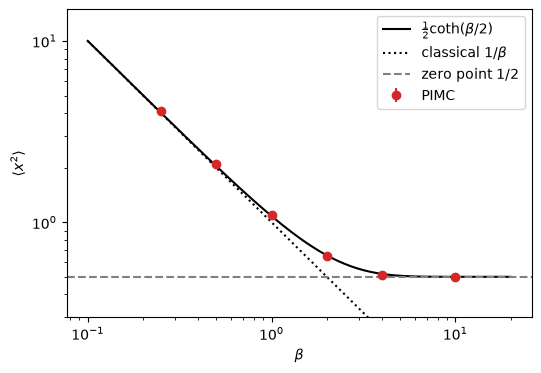

CHECK 1 (MC within 3 sigma of exact lattice <x^2> at every beta): PASS


In [2]:
betas = np.array([0.25, 0.5, 1, 2, 4, 10])
Ms = [max(8, 2 * int(np.ceil(b / 0.25 / 2))) for b in betas]     # eps <= 0.25, at least 8 beads
est, err, lat = [], [], []
for b, M in zip(betas, Ms):
    a = x2_series(run(b, M, 20_000, seed=10)[0])
    est.append(a.mean()); err.append(binned_error(a)); lat.append(x2_lattice(b, M))
est, err, lat = map(np.array, (est, err, lat))
z = (est - lat) / err
for b, M, e, s, l, zz in zip(betas, Ms, est, err, lat, z):
    print(f"beta = {b:5.2f}  M = {M:3d}   MC {e:.4f} +- {s:.4f}   lattice {l:.4f}   "
          f"continuum {x2_continuum(b):.4f}   z = {zz:+.2f}")

bb = np.logspace(-1, 1.3, 200)
plt.figure(figsize=(6, 4))
plt.loglog(bb, x2_continuum(bb), "k-", label=r"$\frac{1}{2}\coth(\beta/2)$")
plt.loglog(bb, 1 / bb, "k:", label=r"classical $1/\beta$")
plt.axhline(0.5, color="gray", ls="--", label="zero point 1/2")
plt.errorbar(betas, est, err, fmt="o", color="C3", label="PIMC")
plt.xlabel(r"$\beta$"); plt.ylabel(r"$\langle x^2\rangle$"); plt.legend(); plt.ylim(0.3, 15)
plt.show()
check("1 (MC within 3 sigma of exact lattice <x^2> at every beta)", np.all(np.abs(z) < 3))

## 2. Two kinds of error

The Trotter error is the difference between the ring and the continuum: deterministic, and second
order in $\varepsilon$. The statistical error is the difference between the Monte Carlo and the ring.
For the oscillator the ring is exactly solvable,
$\langle x^2\rangle_M = \frac{\varepsilon}{2\sinh\varepsilon\tilde\omega}\coth\frac{\beta\tilde\omega}{2}$ with
$\cosh\varepsilon\tilde\omega = 1 + \varepsilon^2/2$, so the two can be shown separately.

M =   8   |lattice - continuum| = 1.47e-02   |MC - lattice| = 1.7e-03   MC error = 5.7e-03
M =  16   |lattice - continuum| = 3.81e-03   |MC - lattice| = 2.2e-03   MC error = 6.8e-03
M =  32   |lattice - continuum| = 9.61e-04   |MC - lattice| = 3.8e-03   MC error = 1.2e-02
M =  64   |lattice - continuum| = 2.41e-04   |MC - lattice| = 2.3e-02   MC error = 1.2e-02
Trotter slope in eps: 1.979


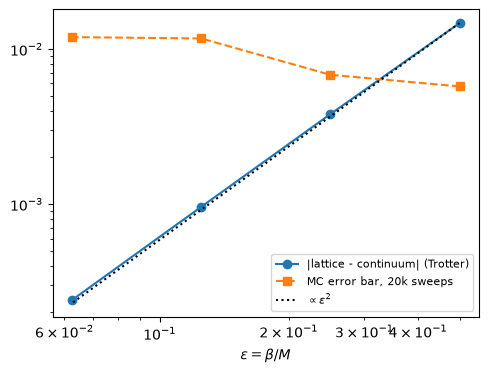

CHECK 2a (Trotter error is second order: slope 2 +- 0.05): PASS
CHECK 2b (MC within 3 sigma of lattice at every M): PASS


In [3]:
beta = 4
Ms2 = np.array([8, 16, 32, 64])
eps2 = beta / Ms2
trot = np.abs(x2_lattice(beta, Ms2) - x2_continuum(beta))
slope = np.polyfit(np.log(eps2), np.log(trot), 1)[0]
mc = [x2_series(run(beta, M, 20_000, seed=20)[0]) for M in Ms2]
dev = np.array([abs(a.mean() - x2_lattice(beta, M)) for a, M in zip(mc, Ms2)])
mc_err = np.array([binned_error(a) for a in mc])
for M, t, d, s in zip(Ms2, trot, dev, mc_err):
    print(f"M = {M:3d}   |lattice - continuum| = {t:.2e}   |MC - lattice| = {d:.1e}   MC error = {s:.1e}")
print(f"Trotter slope in eps: {slope:.3f}")

plt.figure(figsize=(5.5, 4))
plt.loglog(eps2, trot, "o-", label="|lattice - continuum| (Trotter)")
plt.loglog(eps2, mc_err, "s--", label="MC error bar, 20k sweeps")
plt.loglog(eps2, trot[0] * (eps2 / eps2[0])**2, "k:", label=r"$\propto\varepsilon^2$")
plt.xlabel(r"$\varepsilon = \beta/M$"); plt.legend(fontsize=8); plt.show()
check("2a (Trotter error is second order: slope 2 +- 0.05)", abs(slope - 2) < 0.05)
check("2b (MC within 3 sigma of lattice at every M)", np.all(dev < 3 * mc_err))

Already at $M = 16$ the Trotter error is below the statistical error of 20k sweeps, so beyond that
more beads buy nothing visible, and (section 6) they make the sampling slower.

## 3. Honest error bars

Successive sweeps are correlated, so $\sigma/\sqrt N$ is too small by $\sqrt{\tau_{\rm int}}$. Binning
averages blocks of $2^k$ sweeps; once blocks are longer than the correlation time they are
independent and the naive error of the blocks reaches a plateau. Is the plateau honest? Run 16
independent chains and compare the scatter of their answers with the error bar each one reports.

beta = 10, M = 40: naive error 0.00100, binned 0.00528, tau_int = 27.1, naive * sqrt(tau) = 0.00521


16 chains at beta = 10, M = 20: scatter 0.0091, mean binned error 0.0065, mean naive error 0.0023


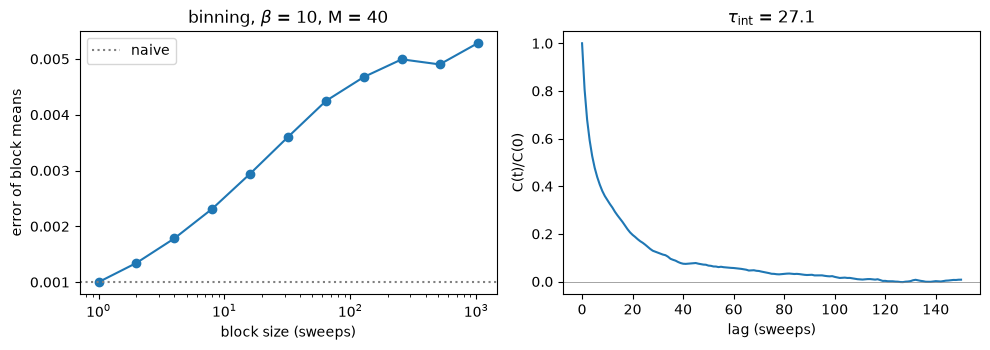

CHECK 3a (binned error = naive * sqrt(tau) within 25%): PASS
CHECK 3b (binned error matches chain-to-chain scatter within 35%): PASS
CHECK 3c (naive error is too small by > 1.5x): PASS


In [4]:
beta, M = 10, 40
paths10 = run(beta, M, 50_000, seed=30)[0]
a10 = x2_series(paths10)
sizes, errs = binning(a10)
tau10 = tau_int(a10)
print(f"beta = {beta}, M = {M}: naive error {naive_error(a10):.5f}, binned {binned_error(a10):.5f}, "
      f"tau_int = {tau10:.1f}, naive * sqrt(tau) = {naive_error(a10) * np.sqrt(tau10):.5f}")

chains = [x2_series(run(10, 20, 10_000, seed=100 + s)[0]) for s in range(16)]
c_est = np.array([c.mean() for c in chains])
c_err = np.array([binned_error(c) for c in chains])
c_naive = np.array([naive_error(c) for c in chains])
print(f"16 chains at beta = 10, M = 20: scatter {c_est.std(ddof=1):.4f}, "
      f"mean binned error {c_err.mean():.4f}, mean naive error {c_naive.mean():.4f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.semilogx(sizes, errs, "o-"); a1.axhline(naive_error(a10), color="gray", ls=":", label="naive")
a1.set_xlabel("block size (sweeps)"); a1.set_ylabel("error of block means"); a1.legend()
a1.set_title(rf"binning, $\beta$ = {beta}, M = {M}")
a2.plot(autocorr(a10, 150)); a2.axhline(0, color="gray", lw=0.5)
a2.set_xlabel("lag (sweeps)"); a2.set_ylabel("C(t)/C(0)"); a2.set_title(rf"$\tau_{{\rm int}}$ = {tau10:.1f}")
plt.tight_layout(); plt.show()
ratio = c_err.mean() / c_est.std(ddof=1)
check("3a (binned error = naive * sqrt(tau) within 25%)",
      abs(binned_error(a10) / (naive_error(a10) * np.sqrt(tau10)) - 1) < 0.25)
check("3b (binned error matches chain-to-chain scatter within 35%)", abs(ratio - 1) < 0.35)
check("3c (naive error is too small by > 1.5x)", c_est.std(ddof=1) / c_naive.mean() > 1.5)

The 35% tolerance in 3b is the sampling error of a standard deviation from 16 numbers (about 18%),
doubled.

**Why the rigid shift is there.** At high temperature the ring is short and floppy, and its centroid
spreads over $\langle \bar x^2\rangle = 1/\beta$. A bead move is sized to its springs, $\sim\sqrt\varepsilon$,
so the centroid only random-walks. Without the shift the answer is badly wrong, and the naive error
bar says it is right.

with shift      <x^2> = 2.062  naive +- 0.020  binned +- 0.050   exact lattice 2.041


without shift   <x^2> = 1.662  naive +- 0.017  binned +- 0.283   exact lattice 2.041


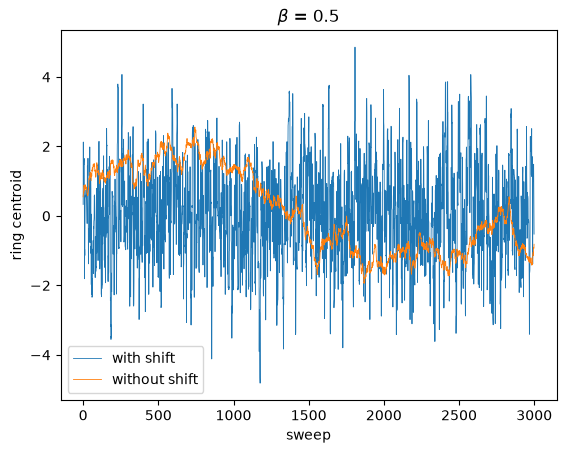

In [5]:
beta, M = 0.5, 8
for ds, label in [(None, "with shift"), (0, "without shift")]:
    p = run(beta, M, 20_000, delta_shift=ds, seed=40)[0]
    a = x2_series(p)
    print(f"{label:14s}  <x^2> = {a.mean():.3f}  naive +- {naive_error(a):.3f}  binned +- {binned_error(a):.3f}"
          f"   exact lattice {x2_lattice(beta, M):.3f}")
    plt.plot(p.mean(axis=1)[:3000], lw=0.6, label=label)
plt.xlabel("sweep"); plt.ylabel("ring centroid"); plt.title(r"$\beta$ = 0.5"); plt.legend(); plt.show()

## 4. The ground state, from the beads

At $\beta = 10$ the excited states carry weight $e^{-10}$, so the histogram of every bead of every
sweep is $|\psi_0(x)|^2 = \pi^{-1/2}e^{-x^2}$, up to the lattice, which makes it a Gaussian of variance
$\langle x^2\rangle_M$ exactly. Wick's theorem then fixes $\langle x^4\rangle = 3\langle x^2\rangle^2$.

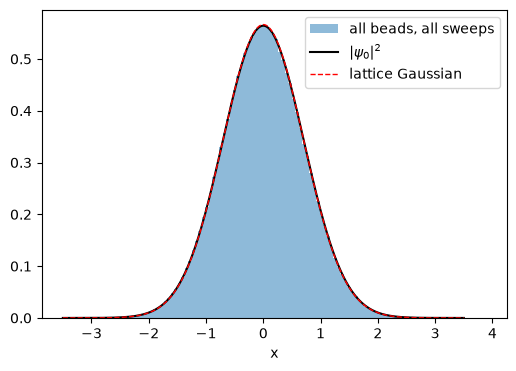

<x^4> = 0.7549 +- 0.0163,  3 <x^2>_M^2 = 0.7386
max |histogram - |psi_0|^2| = 0.0051
CHECK 4 (Wick: <x^4> = 3 <x^2>_M^2 within 3 sigma): PASS


In [6]:
beads = paths10.ravel()
a4 = (paths10**4).mean(axis=1)
xx = np.linspace(-3.5, 3.5, 300)
s2 = x2_lattice(10, 40)
plt.figure(figsize=(6, 4))
plt.hist(beads, bins=120, density=True, alpha=0.5, label="all beads, all sweeps")
plt.plot(xx, np.exp(-xx**2) / np.sqrt(np.pi), "k-", label=r"$|\psi_0|^2$")
plt.plot(xx, np.exp(-xx**2 / (2 * s2)) / np.sqrt(2 * np.pi * s2), "r--", lw=1, label="lattice Gaussian")
plt.xlabel("x"); plt.legend(); plt.show()
print(f"<x^4> = {a4.mean():.4f} +- {binned_error(a4):.4f},  3 <x^2>_M^2 = {3 * s2**2:.4f}")
counts, edges = np.histogram(beads, bins=60, range=(-3, 3), density=True)
mid = (edges[1:] + edges[:-1]) / 2
print(f"max |histogram - |psi_0|^2| = {np.abs(counts - np.exp(-mid**2) / np.sqrt(np.pi)).max():.4f}")
check("4 (Wick: <x^4> = 3 <x^2>_M^2 within 3 sigma)", abs(a4.mean() - 3 * s2**2) < 3 * binned_error(a4))

## 5. The spectrum, from imaginary time

$G(t) = \langle x_j x_{j+t}\rangle$ around the ring is a sum of $e^{-(E_m - E_n)\varepsilon t}$ terms. For
the oscillator $x$ only connects neighbouring levels, all spaced by one gap, so on the ring
$G \propto \cosh\big(\tilde\omega(\beta/2 - \varepsilon t)\big)$ exactly, and the effective gap
$\mathrm{arccosh}\frac{G(t-1)+G(t+1)}{2G(t)}/\varepsilon$ is $\tilde\omega$ at every $t$ (on this lattice
$\tilde\omega = 0.9975$, against a continuum gap of 1). Errors come from the jackknife, since the
effective gap is a nonlinear function of averages.

t = 1:  effective gap 0.9839 +- 0.0116
t = 2:  effective gap 0.9815 +- 0.0145
t = 3:  effective gap 0.9860 +- 0.0148
t = 4:  effective gap 0.9666 +- 0.0201
lattice gap w~ = 0.9974, continuum 1


/Users/zhen/Documents/Code/Python/PHYS7321_COMP/COMP2026/agentic/06_Statistics_and_Monte_Carlo/pimc.py:127: RuntimeWarning: invalid value encountered in arccosh
  return np.arccosh((G[:-2] + G[2:]) / (2 * G[1:-1])) / eps


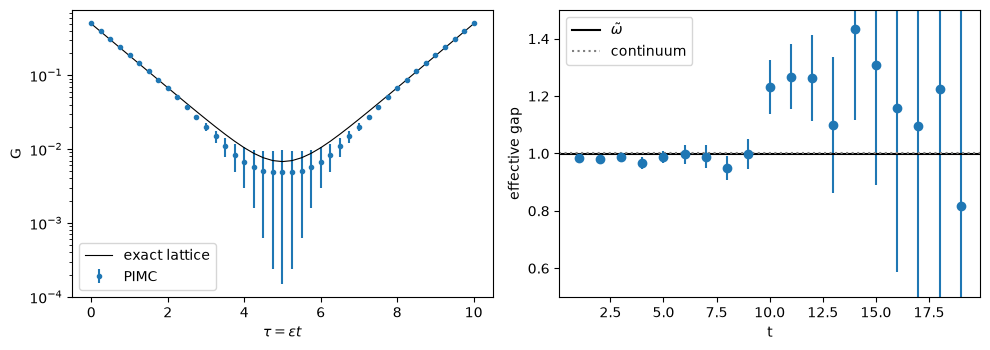

CHECK 5 (effective gap at t = 1 equals w~ within 3 sigma): PASS


In [7]:
eps = 10 / 40
G = correlator(paths10)
gap, gerr = jackknife(G, lambda g: effective_gap(g, eps))
t = np.arange(1, 40)
w = lattice_omega(eps)
for i in range(4):
    print(f"t = {t[i]}:  effective gap {gap[i]:.4f} +- {gerr[i]:.4f}")
print(f"lattice gap w~ = {w:.4f}, continuum 1")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
Gm, Ge = jackknife(G, lambda g: g)
a1.errorbar(np.arange(41) * eps, Gm, Ge, fmt=".", label="PIMC")
a1.plot(np.arange(41) * eps, transfer_correlator(harmonic, 10, 40), "k-", lw=0.8, label="exact lattice")
a1.set_yscale("log"); a1.set_xlabel(r"$\tau = \varepsilon t$"); a1.set_ylabel("G"); a1.legend()
a2.errorbar(t[:20], gap[:20], gerr[:20], fmt="o")
a2.axhline(w, color="k", label=r"$\tilde\omega$"); a2.axhline(1, color="gray", ls=":", label="continuum")
a2.set_ylim(0.5, 1.5); a2.set_xlabel("t"); a2.set_ylabel("effective gap"); a2.legend()
plt.tight_layout(); plt.show()
check("5 (effective gap at t = 1 equals w~ within 3 sigma)", abs(gap[0] - w) < 3 * gerr[0])

The error bars grow fast with $t$: $G$ falls exponentially while its noise doesn't. This is the
signal-to-noise problem of every lattice spectroscopy calculation, and the reason to fit at the
smallest $t$ where the excited contributions are gone (here there are none, so $t = 1$ is fine).
The estimates at different $t$ come from the same paths and are strongly correlated, so averaging
them with inverse-variance weights would give a much too small error bar; the check uses $t = 1$ alone.

## 6. Critical slowing down, and a cure

The springs have stiffness $1/\varepsilon = M/\beta$. Single-bead moves relax the short-wavelength
modes of the ring at once, but a long-wavelength mode only drifts. Fixed $\beta$, growing $M$: watch
$\tau_{\rm int}$. The cure is Metropolis moves along the ring's lowest Fourier modes,
$x_j \to x_j + A\cos(2\pi kj/M + \phi)$, with $A$ sized to each mode's width. Only modes with
imaginary-time wavelength longer than $1/\omega$ are slow, about $\beta\omega/2\pi$ of them, a number
that does not grow with $M$, so a fixed $k_{\max} = 8$ is enough here.

M =  20  k_max = 0   tau_int =     9.4   ms per independent sample =    1.96   z = +0.51


M =  20  k_max = 8   tau_int =     4.7   ms per independent sample =    2.83   z = +1.71


M =  40  k_max = 0   tau_int =    23.3   ms per independent sample =    4.90   z = +0.99


M =  40  k_max = 8   tau_int =     6.2   ms per independent sample =    3.40   z = +0.26


M =  80  k_max = 0   tau_int =    98.4   ms per independent sample =   19.80   z = +0.59


M =  80  k_max = 8   tau_int =     7.0   ms per independent sample =    3.84   z = -0.79


M = 160  k_max = 0   tau_int =   223.5   ms per independent sample =   52.40   z = -1.26


M = 160  k_max = 8   tau_int =     8.3   ms per independent sample =    4.97   z = +0.94


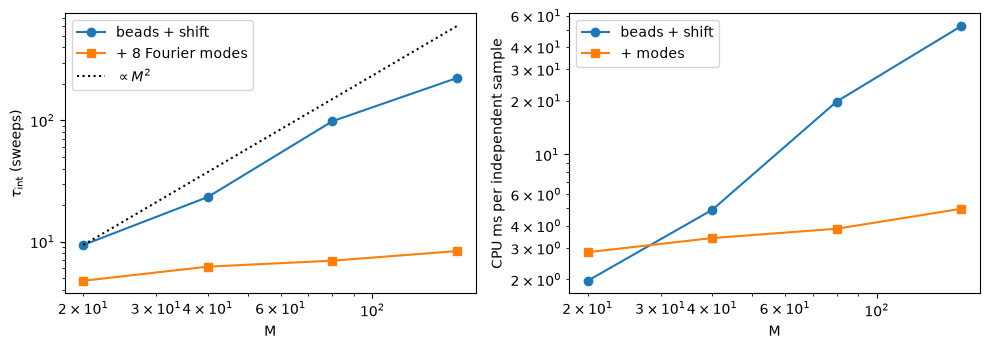

tau_int ~ M^1.58 with bead moves only
CHECK 6a (bead-only tau grows at least like M^1.5): PASS
CHECK 6b (with modes, tau at M = 160 below 20): PASS
CHECK 6c (all runs within 3 sigma of lattice): PASS


In [8]:
import time
beta = 10
Ms6 = [20, 40, 80, 160]
rows = []
for M in Ms6:
    for k_max, n in [(0, {20: 20_000, 40: 20_000, 80: 50_000, 160: 150_000}[M]), (8, 15_000)]:
        t0 = time.time()
        a = x2_series(run(beta, M, n, k_max=k_max, seed=60)[0])
        sec = (time.time() - t0) / n
        tau = tau_int(a)
        rows.append((M, k_max, tau, sec * tau * 1e3, (a.mean() - x2_lattice(beta, M)) / binned_error(a)))
        print(f"M = {M:3d}  k_max = {k_max}   tau_int = {tau:7.1f}   ms per independent sample = "
              f"{rows[-1][3]:7.2f}   z = {rows[-1][4]:+.2f}")
rows = np.array(rows)
loc, mod = rows[rows[:, 1] == 0], rows[rows[:, 1] == 8]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.loglog(loc[:, 0], loc[:, 2], "o-", label="beads + shift")
a1.loglog(mod[:, 0], mod[:, 2], "s-", label="+ 8 Fourier modes")
a1.loglog(loc[:, 0], loc[0, 2] * (loc[:, 0] / loc[0, 0])**2, "k:", label=r"$\propto M^2$")
a1.set_xlabel("M"); a1.set_ylabel(r"$\tau_{\rm int}$ (sweeps)"); a1.legend()
a2.loglog(loc[:, 0], loc[:, 3], "o-", label="beads + shift"); a2.loglog(mod[:, 0], mod[:, 3], "s-", label="+ modes")
a2.set_xlabel("M"); a2.set_ylabel("CPU ms per independent sample"); a2.legend()
plt.tight_layout(); plt.show()
p_loc = np.polyfit(np.log(loc[:, 0]), np.log(loc[:, 2]), 1)[0]
print(f"tau_int ~ M^{p_loc:.2f} with bead moves only")
check("6a (bead-only tau grows at least like M^1.5)", p_loc > 1.5)
check("6b (with modes, tau at M = 160 below 20)", mod[-1, 2] < 20)
check("6c (all runs within 3 sigma of lattice)", np.all(np.abs(rows[:, 4]) < 3))

## 7. A double well: tunneling

$V = (x^2 - a^2)^2$ with $a = 1.4$: barrier height $a^4 = 3.84$, wells of curvature $8a^2$
($\omega \approx 4$). There is no formula, but finite differences give the spectrum and the transfer
matrix gives the exact lattice answer, so there is still a check. The two lowest levels are the
symmetric and antisymmetric combinations of the well states, split by tunneling.

finite differences: E = [1.7705  1.87867 4.29331 5.54843]   splitting 0.10817
lattice eps = 0.1:  E = [1.76039 1.86745 4.27953]   splitting 0.10706


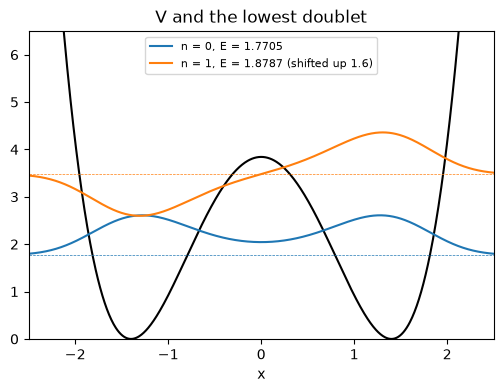

In [9]:
A = 1.4
dw = lambda x: (x**2 - A**2)**2
xg, E_dw, psi_dw = fd_spectrum(dw, k=6)
split_fd = E_dw[1] - E_dw[0]
eps_dw = 0.1
_, lam_dw, _ = transfer(dw, eps_dw)
E_lat = -np.log(lam_dw[:3]) / eps_dw
print("finite differences: E =", np.round(E_dw[:4], 5), f"  splitting {split_fd:.5f}")
print(f"lattice eps = {eps_dw}:  E =", np.round(E_lat, 5), f"  splitting {E_lat[1] - E_lat[0]:.5f}")
plt.figure(figsize=(6, 4))
xs = xg[np.abs(xg) < 2.3]
plt.plot(xs, dw(xs), "k-")
for n, off in [(0, 0.0), (1, 1.6)]:                           # n = 1 lifted for visibility
    base = E_dw[n] + off
    plt.axhline(base, color=f"C{n}", lw=0.5, ls="--")
    plt.plot(xg, base + 1.2 * psi_dw[:, n] * np.sign(psi_dw[-len(xg) // 3, n]),
             color=f"C{n}", label=f"n = {n}, E = {E_dw[n]:.4f}" + (" (shifted up 1.6)" if off else ""))
plt.ylim(0, 6.5); plt.xlim(-2.5, 2.5); plt.xlabel("x"); plt.legend(fontsize=8, loc="upper center"); plt.title("V and the lowest doublet")
plt.show()

**Sampling it.** Beads, shift, and modes alone fail here, and their error bars don't say so. The
reason is the number of instantons, the places where the path crosses from one well to the other.
Changing it means dragging a whole stretch of path over the barrier, so it is far slower than
anything $\tau_{\rm int}$ of $x^2$ can see within a run, and each chain sits at its own value.
The fix uses $V(-x) = V(x)$: reflect a random stretch of the ring, $x \to -x$. The potential doesn't
change, only the two springs at the ends, so a flip whose ends sit on kinks is cheap; it moves
instantons and creates or removes pairs, and the move is its own inverse.

flips =  0  seed 11:  <x^2> = 1.5312 +- 0.0110   z =  -6.0   mean sign changes 3.87


flips =  0  seed 12:  <x^2> = 1.5911 +- 0.0143   z =  -0.5   mean sign changes 2.64


flips = 20  seed 11:  <x^2> = 1.5956 +- 0.0131   z =  -0.2   mean sign changes 2.51


flips = 20  seed 12:  <x^2> = 1.5826 +- 0.0130   z =  -1.2   mean sign changes 2.68
exact lattice <x^2> = 1.5979,  continuum (finite differences) = 1.5922


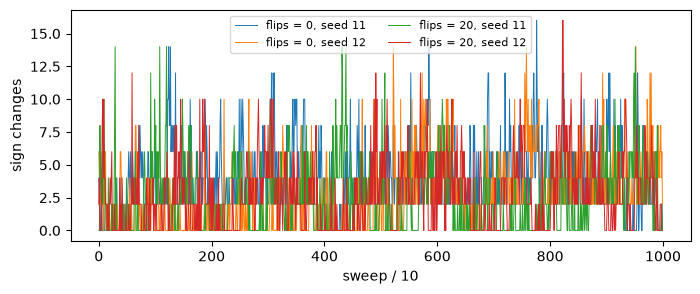

CHECK 7a (with flips: both seeds within 3 sigma of exact lattice): PASS
CHECK 7b (with flips: the two seeds agree on the instanton count within 15%): PASS


In [10]:
beta, M = 20, 200
x2_exact = transfer_x2(dw, beta, M)
opts = dict(delta_shift=2 * A, k_max=24, curv=8 * A**2, V=dw, n_therm=2000)
res = {}
for n_flip in (0, 20):
    for seed in (11, 12):
        p = run(beta, M, 10_000, n_flip=n_flip, seed=seed, **opts)[0]
        a = x2_series(p)
        res[n_flip, seed] = (a.mean(), binned_error(a), sign_changes(p).mean(), p)
        print(f"flips = {n_flip:2d}  seed {seed}:  <x^2> = {a.mean():.4f} +- {binned_error(a):.4f}   "
              f"z = {(a.mean() - x2_exact) / binned_error(a):+5.1f}   mean sign changes {res[n_flip, seed][2]:.2f}")
print(f"exact lattice <x^2> = {x2_exact:.4f},  continuum (finite differences) = {fd_thermal_x2(dw, beta):.4f}")
fig, ax = plt.subplots(figsize=(8, 3))
for (nf, s), r in res.items():
    ax.plot(sign_changes(r[3])[:10_000:10], lw=0.7, label=f"flips = {nf}, seed {s}")
ax.set_xlabel("sweep / 10"); ax.set_ylabel("sign changes"); ax.legend(fontsize=8, ncol=2); plt.show()
zs = [(res[20, s][0] - x2_exact) / res[20, s][1] for s in (11, 12)]
check("7a (with flips: both seeds within 3 sigma of exact lattice)", max(map(abs, zs)) < 3)
check("7b (with flips: the two seeds agree on the instanton count within 15%)",
      abs(res[20, 11][2] / res[20, 12][2] - 1) < 0.15)

## 8. Instantons, and the tunneling splitting

At $\beta = 40$ the ring is long compared with the instanton width $\sim 1/\omega$ and the typical
spacing between instantons $\sim 1/\Delta E$. Individual paths sit in one well and jump. The
correlator now has a slow piece from the doublet on top of fast pieces from the levels above the
barrier ($E_2 - E_0 \approx 2.5$, gone by $\tau \approx 2.5$). By parity $\langle 0|x|0\rangle = \langle 1|x|1\rangle = 0$, so
the doublet piece is exactly $\propto\cosh\big(\Delta E(\beta/2 - \tau)\big)$.

The neighbour-difference effective gap of section 5 is useless here: the curvature of $G$ over
one step is $\sim (\varepsilon\Delta E)^2 \approx 10^{-4}$ of $G$, far below the noise. A long baseline
works instead, $G(\tau_1)/G(\beta/2) = \cosh\big(\Delta E(\beta/2 - \tau_1)\big)$, a ratio of about 3.

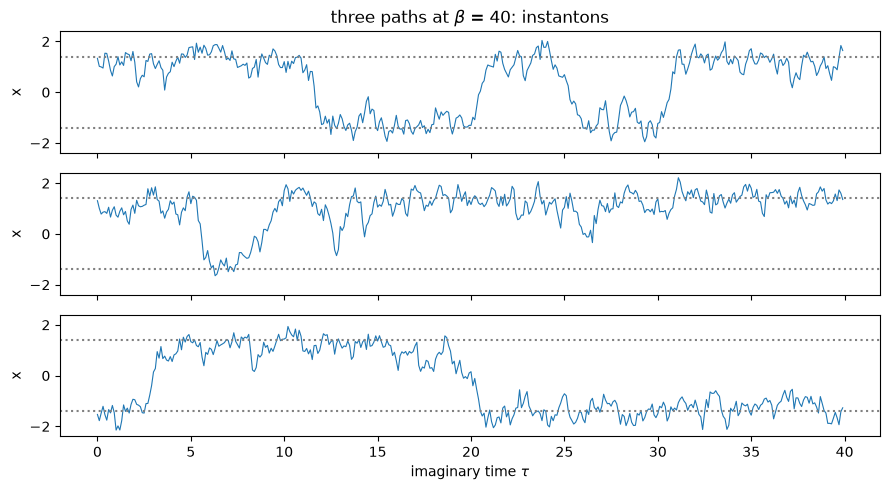

<x^2> = 1.5782 +- 0.0065   exact lattice 1.5831


tau_1 =  1.0:  PIMC 0.1249 +- 0.0141   exact lattice correlator 0.1071
tau_1 =  2.0:  PIMC 0.1257 +- 0.0147   exact lattice correlator 0.1071
tau_1 =  3.0:  PIMC 0.1266 +- 0.0153   exact lattice correlator 0.1071
tau_1 =  4.0:  PIMC 0.1275 +- 0.0160   exact lattice correlator 0.1071
tau_1 =  5.0:  PIMC 0.1284 +- 0.0167   exact lattice correlator 0.1071
tau_1 =  6.0:  PIMC 0.1292 +- 0.0175   exact lattice correlator 0.1071
tau_1 =  7.0:  PIMC 0.1301 +- 0.0183   exact lattice correlator 0.1071
tau_1 =  8.0:  PIMC 0.1310 +- 0.0191   exact lattice correlator 0.1071
tau_1 =  9.0:  PIMC 0.1316 +- 0.0200   exact lattice correlator 0.1071
tau_1 = 10.0:  PIMC 0.1319 +- 0.0209   exact lattice correlator 0.1071
tau_1 = 11.0:  PIMC 0.1320 +- 0.0219   exact lattice correlator 0.1071
tau_1 = 12.0:  PIMC 0.1320 +- 0.0229   exact lattice correlator 0.1071
tau_1 = 13.0:  PIMC 0.1318 +- 0.0238   exact lattice correlator 0.1071
lattice splitting 0.1071,  continuum splitting 0.1082


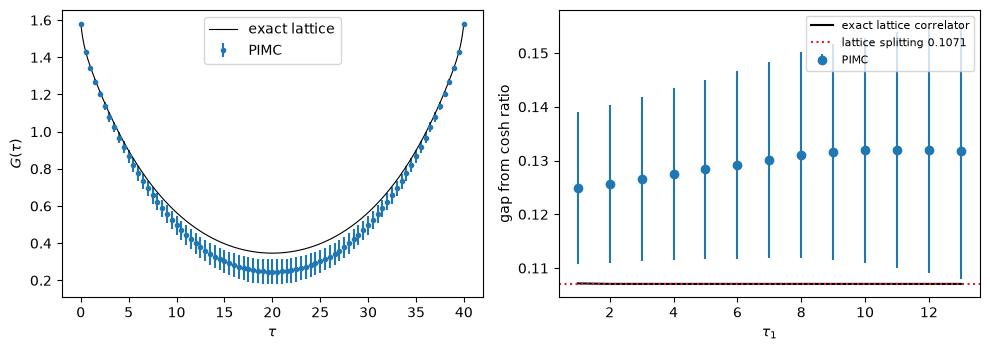

CHECK 8a (beta = 40: <x^2> within 3 sigma of exact lattice): PASS
CHECK 8b (cosh-ratio gap within 3 sigma of the exact lattice correlator for tau_1 >= 3): PASS
CHECK 8c (exact lattice correlator's gap equals the lattice splitting to 1% for tau_1 >= 3): PASS


In [11]:
beta, M = 40, 400
p40 = run(beta, M, 20_000, n_flip=40, seed=13, **{**opts, "k_max": 48})[0]
tau_ax = np.arange(M) * beta / M
fig, ax = plt.subplots(3, 1, figsize=(9, 5), sharex=True)
for axi, s in zip(ax, (2500, 6000, 9500)):
    axi.plot(tau_ax, p40[s], lw=0.8); axi.axhline(A, color="gray", ls=":"); axi.axhline(-A, color="gray", ls=":")
    axi.set_ylabel("x"); axi.set_ylim(-2.4, 2.4)
ax[-1].set_xlabel(r"imaginary time $\tau$"); ax[0].set_title(r"three paths at $\beta$ = 40: instantons")
plt.tight_layout(); plt.show()

a40 = x2_series(p40)
x2_40 = transfer_x2(dw, beta, M)
print(f"<x^2> = {a40.mean():.4f} +- {binned_error(a40):.4f}   exact lattice {x2_40:.4f}")

G40 = correlator(p40)
eps40 = beta / M
G40_exact = transfer_correlator(dw, beta, M)
t1s = np.arange(10, 140, 10)                                 # tau_1 = 1 .. 13
gaps = [jackknife(G40, lambda g, t1=t1: cosh_gap(g, eps40, t1)) for t1 in t1s]
gm, ge = np.array(gaps).T
gx = np.array([cosh_gap(G40_exact, eps40, t1) for t1 in t1s])
split_lat = E_lat[1] - E_lat[0]
for t1, m, e, x in zip(t1s, gm, ge, gx):
    print(f"tau_1 = {t1 * eps40:4.1f}:  PIMC {m:.4f} +- {e:.4f}   exact lattice correlator {x:.4f}")
print(f"lattice splitting {split_lat:.4f},  continuum splitting {split_fd:.4f}")
Gm40, Ge40 = jackknife(G40, lambda g: g)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
tt = np.arange(M + 1) * eps40
a1.errorbar(tt[::5], Gm40[::5], Ge40[::5], fmt=".", label="PIMC")
a1.plot(tt, G40_exact, "k-", lw=0.8, label="exact lattice")
a1.set_xlabel(r"$\tau$"); a1.set_ylabel(r"$G(\tau)$"); a1.legend()
a2.errorbar(t1s * eps40, gm, ge, fmt="o", label="PIMC")
a2.plot(t1s * eps40, gx, "k-", label="exact lattice correlator")
a2.axhline(split_lat, color="C3", ls=":", label=f"lattice splitting {split_lat:.4f}")
a2.set_xlabel(r"$\tau_1$"); a2.set_ylabel("gap from cosh ratio"); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()
far = t1s * eps40 >= 3
check("8a (beta = 40: <x^2> within 3 sigma of exact lattice)", abs(a40.mean() - x2_40) < 3 * binned_error(a40))
check("8b (cosh-ratio gap within 3 sigma of the exact lattice correlator for tau_1 >= 3)",
      np.all(np.abs(gm[far] - gx[far]) < 3 * ge[far]))
check("8c (exact lattice correlator's gap equals the lattice splitting to 1% for tau_1 >= 3)",
      np.allclose(gx[far], split_lat, rtol=0.01))

In the exact correlator the levels above the barrier shift the estimate only in the fourth digit
at $\tau_1 = 1$, and not at all past $\tau_1 \approx 3$. The Monte Carlo points at different $\tau_1$ share
the same $G(\beta/2)$ and are strongly correlated; they are one measurement, good to about 15%,
limited by the slow tunneling sector. A long baseline is right for a small gap and wrong for a
large one: for the oscillator $G(\beta/2)$ is $\cosh 5 \approx 74$ times below $G(0)$ and pure noise. The lattice splitting at $\varepsilon = 0.1$ differs from the
continuum one by about 1%, a Trotter error well inside the Monte Carlo error bars.

## 9. Summary of checks

In [12]:
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\n{sum(checks.values())}/{len(checks)} passed")

PASS  1 (MC within 3 sigma of exact lattice <x^2> at every beta)
PASS  2a (Trotter error is second order: slope 2 +- 0.05)
PASS  2b (MC within 3 sigma of lattice at every M)
PASS  3a (binned error = naive * sqrt(tau) within 25%)
PASS  3b (binned error matches chain-to-chain scatter within 35%)
PASS  3c (naive error is too small by > 1.5x)
PASS  4 (Wick: <x^4> = 3 <x^2>_M^2 within 3 sigma)
PASS  5 (effective gap at t = 1 equals w~ within 3 sigma)
PASS  6a (bead-only tau grows at least like M^1.5)
PASS  6b (with modes, tau at M = 160 below 20)
PASS  6c (all runs within 3 sigma of lattice)
PASS  7a (with flips: both seeds within 3 sigma of exact lattice)
PASS  7b (with flips: the two seeds agree on the instanton count within 15%)
PASS  8a (beta = 40: <x^2> within 3 sigma of exact lattice)
PASS  8b (cosh-ratio gap within 3 sigma of the exact lattice correlator for tau_1 >= 3)
PASS  8c (exact lattice correlator's gap equals the lattice splitting to 1% for tau_1 >= 3)

16/16 passed
